## Bước 1: Chuẩn bị dữ liệu 

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os

In [162]:
data_path=os.path.join('..', 'DATA', 'raw', 'AEP_hourly.csv')
df=pd.read_csv(data_path)
df.head(10)

,Datetime,AEP_MW
0,2004-12-31 01:00:00,13478.0
1,2004-12-31 02:00:00,12865.0
2,2004-12-31 03:00:00,12577.0
3,2004-12-31 04:00:00,12517.0
4,2004-12-31 05:00:00,12670.0
5,2004-12-31 06:00:00,13038.0
6,2004-12-31 07:00:00,13692.0
7,2004-12-31 08:00:00,14297.0
8,2004-12-31 09:00:00,14719.0
9,2004-12-31 10:00:00,14941.0


## Thông tin dữ liệu

In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  121273 non-null  object 
 1   AEP_MW    121273 non-null  float64
dtypes: float64(1), object(1)
memory usage: 1.9+ MB


In [164]:
#ép sang datetime
df['Datetime'] = pd.to_datetime(df['Datetime'])
df=df.set_index('Datetime').sort_index()
df.columnd=['MW']
print(f"index : {df.index.min()} -> {df.index.max()}")
print(f"total hour : {len(df):,}")
print(f"total year : {(df.index.max() - df.index.min()).days/365:.1f} year")

index : 2004-10-01 01:00:00 -> 2018-08-03 00:00:00
total hour : 121,273
total year : 13.8 year


C:\Users\Windows\AppData\Local\Temp\ipykernel_22552\761660783.py:4: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.columnd=['MW']


## Thống kê mô tả

In [165]:
df.describe()

,AEP_MW
count,121273.000000
mean,15499.513717
std,2591.399065
min,9581.000000
25%,13630.000000
50%,15310.000000
75%,17200.000000
max,25695.000000


## Xử lý dữ liệu

In [166]:
dpt=df.index.duplicated().sum()
print(f" Duplicated index: {dpt}")
#xử lý 
if dpt>0:
    df=df[~df.index.duplicated(keep='first')]
    print(f"Xóa {dpt} duplicated trong data")
#sắp xếp lại bản ghi
before_hours=int((df.index.max()-df.index.min()).total_seconds()/3600)+1
affter_hours=len(df)#số bản ghi sau khi xử lý
print(f"Before hours : {before_hours:,}")
print(f"Affter hours : {affter_hours}")
print(f"Missing hours : {before_hours-affter_hours}")

 Duplicated index: 4
Xóa 4 duplicated trong data
Before hours : 121,296
Affter hours : 121269
Missing hours : 27


## Trực quan dữ liệu 

C:\Users\Windows\AppData\Local\Temp\ipykernel_22552\588156024.py:46: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  last_year=df.last('365D')
C:\Users\Windows\AppData\Local\Temp\ipykernel_22552\588156024.py:52: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  last_week=df.last('7D')


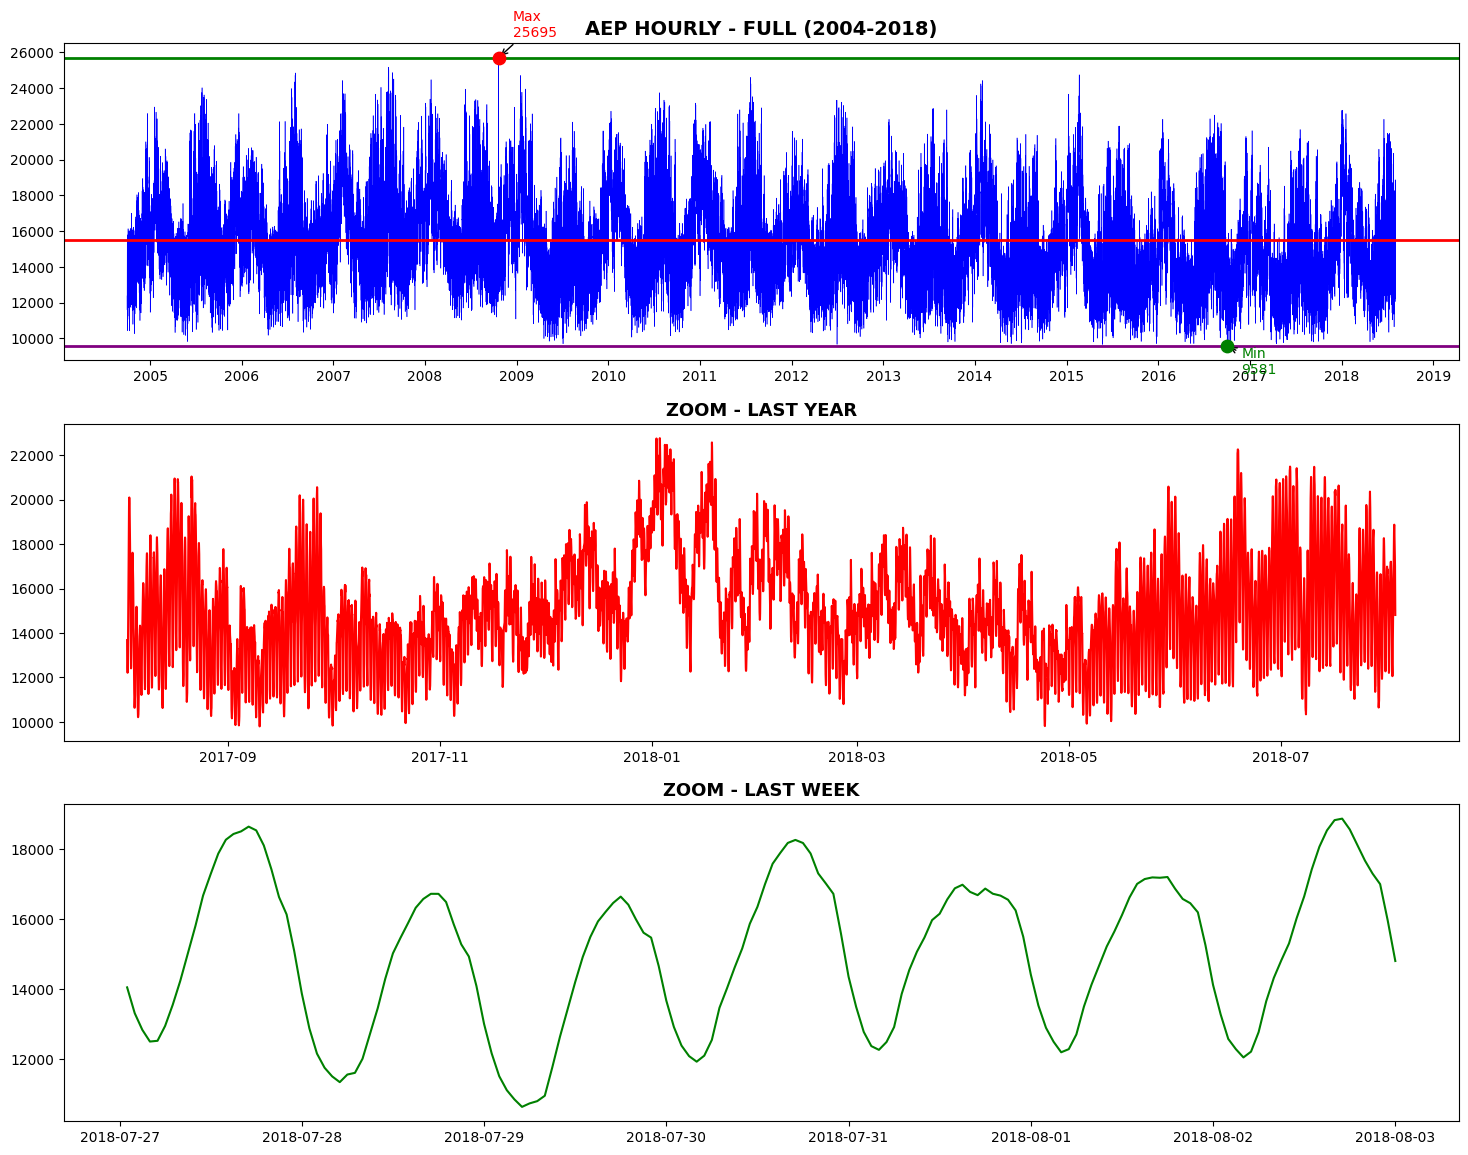

In [167]:
fig, axes=plt.subplots(3,1, figsize=(18,14))
#toàn bộ chuỗi thời gian
#thống kê 
mean_val=df['AEP_MW'].mean()
min_val=df['AEP_MW'].min()
max_val=df['AEP_MW'].max()

axes[0].plot(df.index, df['AEP_MW'], lw=0.4, color='blue')
axes[0].set_title('AEP HOURLY - FULL (2004-2018)', fontsize=14, fontweight='bold')
axes[0].set_label('AEP_MW')
# Mean
axes[0].axhline(mean_val,color='red',
                lw=2,label=f'Mean = {mean_val:.0f}')
# Max
axes[0].axhline(max_val,color='green',
                lw=2,label=f'Max = {max_val:.0f}')

# Min
axes[0].axhline(min_val,color='purple',
                lw=2,label=f'Min = {min_val:.0f}')

# Vị trí Min và Max
min_idx = df['AEP_MW'].idxmin()
max_idx = df['AEP_MW'].idxmax()
# Vẽ điểm
axes[0].scatter(max_idx,max_val,
               color='red',s=80,zorder=5)

axes[0].scatter(min_idx,min_val,
                color='green',s=80,zorder=5)

# Ghi chú
axes[0].annotate(f'Max\n{max_val:.0f}',(max_idx, max_val),xytext=(10,15),
                 textcoords='offset points',color='red',fontsize=10,
                 arrowprops=dict(arrowstyle='->'))

axes[0].annotate(f'Min\n{min_val:.0f}',(min_idx, min_val),xytext=(10,-20),
                 textcoords='offset points',color='green',fontsize=10,
                 arrowprops=dict(arrowstyle='->'))

# Định dạng trục X chỉ hiện năm (ví dụ: 2004, 2005,...)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].xaxis.set_major_locator(mdates.YearLocator())   # Đánh dấu mỗi năm

#trực quan 365 ngày 
last_year=df.last('365D')
axes[1].plot(last_year.index, last_year['AEP_MW'], color='red')
axes[1].set_title('ZOOM - LAST YEAR', fontsize=13, fontweight='bold')
axes[1].set_label('AEP_MW')

#trực quan theo tuần 
last_week=df.last('7D')
axes[2].plot(last_week.index, last_week['AEP_MW'], color='green')
axes[2].set_title('ZOOM - LAST WEEK', fontsize=13, fontweight='bold')
axes[2].set_label('AEP_MW')

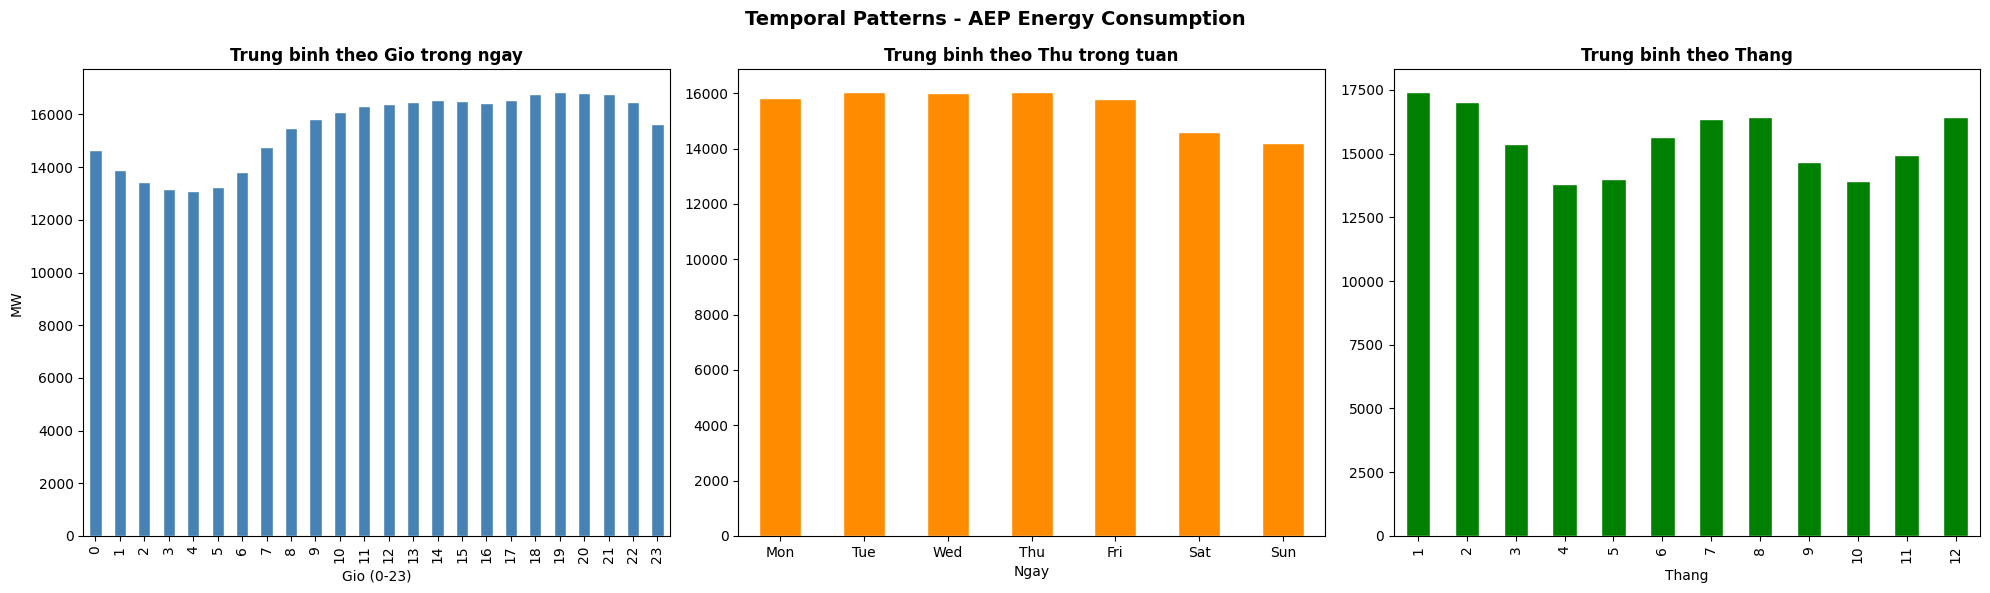

Peak hour    : 19h (gio cao diem)
Off-peak hour: 4h (gio thap diem)
Peak month   : 1 (thang tieu thu nhieu nhat)
Saved: ..\data\raw\AEP_cleaned.csv
Shape : (121269, 1)


In [168]:
df_eda = df.copy()
# Trích xuất các thành phần thời gian từ index (DatetimeIndex)
df_eda['hour']  = df_eda.index.hour       
df_eda['dow']   = df_eda.index.dayofweek   
df_eda['month'] = df_eda.index.month    
df_eda['year']  = df_eda.index.year         
# Tạo figure với 3 biểu đồ nằm ngang
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Temporal Patterns - AEP Energy Consumption', fontsize=14, fontweight='bold')

df_eda.groupby('hour')['AEP_MW'].mean().plot(kind='bar', ax=axes[0],
                                          color='steelblue', edgecolor='white')
axes[0].set_title('Trung binh theo Gio trong ngay', fontweight='bold')
axes[0].set_xlabel('Gio (0-23)')  
axes[0].set_ylabel('MW')          

dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df_eda.groupby('dow')['AEP_MW'].mean().plot(kind='bar', ax=axes[1],
                                         color='darkorange', edgecolor='white')
axes[1].set_title('Trung binh theo Thu trong tuan', fontweight='bold')
# set_xticklabels: thay nhãn số 0-6 bằng tên thứ; rotation=0: chữ nằm ngang
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_xlabel('Ngay')

df_eda.groupby('month')['AEP_MW'].mean().plot(kind='bar', ax=axes[2],
                                           color='green', edgecolor='white')
axes[2].set_title('Trung binh theo Thang', fontweight='bold')
axes[2].set_xlabel('Thang')
plt.tight_layout()
plt.show()

# idxmax() trả về index của giá trị lớn nhất (giờ cao điểm)
peak_hour  = df_eda.groupby('hour')['AEP_MW'].mean().idxmax()
# idxmin() trả về index của giá trị nhỏ nhất (giờ thấp điểm)
off_hour   = df_eda.groupby('hour')['AEP_MW'].mean().idxmin()
peak_month = df_eda.groupby('month')['AEP_MW'].mean().idxmax()

print(f"Peak hour    : {peak_hour}h (gio cao diem)")
print(f"Off-peak hour: {off_hour}h (gio thap diem)")
print(f"Peak month   : {peak_month} (thang tieu thu nhieu nhat)")

out_path = os.path.join('..', 'data', 'raw', 'AEP_cleaned.csv')

df.to_csv(out_path)
print(f"Saved: {out_path}")
print(f"Shape : {df.shape}") 

## Bước 2: tạo lag features và tách X,y

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os  
import seaborn as sns
import warnings

## Tạo hàm lag featueres

In [170]:
def create_lag_feature(series: pd.Series, n_lags: int=24):
    result=pd.DataFrame({'y' : series})
    #tạo 24 lag
    for lag in range(1, n_lag+1):
        result[f'lag {lag}']=series.shift(lag)#chuyển chuỗi thành từng lag
    return result.dropna()#xóa hàng đầu bị NaN

n_lag=24
df_lag=create_lag_feature(df['AEP_MW'], n_lags=n_lag)
print(f"Sau khi chia các lag feature : {df_lag.shape}")
print(f"columns : ")
df_lag.head()

Sau khi chia các lag feature : (121245, 25)
columns : 


,y,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 9,...,lag 15,lag 16,lag 17,lag 18,lag 19,lag 20,lag 21,lag 22,lag 23,lag 24
Datetime,,,,,,,,,,,,,,,,,,,,,
2004-10-02 01:00:00,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,...,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
2004-10-02 02:00:00,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,...,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2004-10-02 03:00:00,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,...,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
2004-10-02 04:00:00,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,...,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
2004-10-02 05:00:00,11142.0,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,...,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


## Phân tích độ tương quan giữa các lag và biến mục tiêu y

C:\Users\Windows\AppData\Local\Temp\ipykernel_22552\3154924207.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


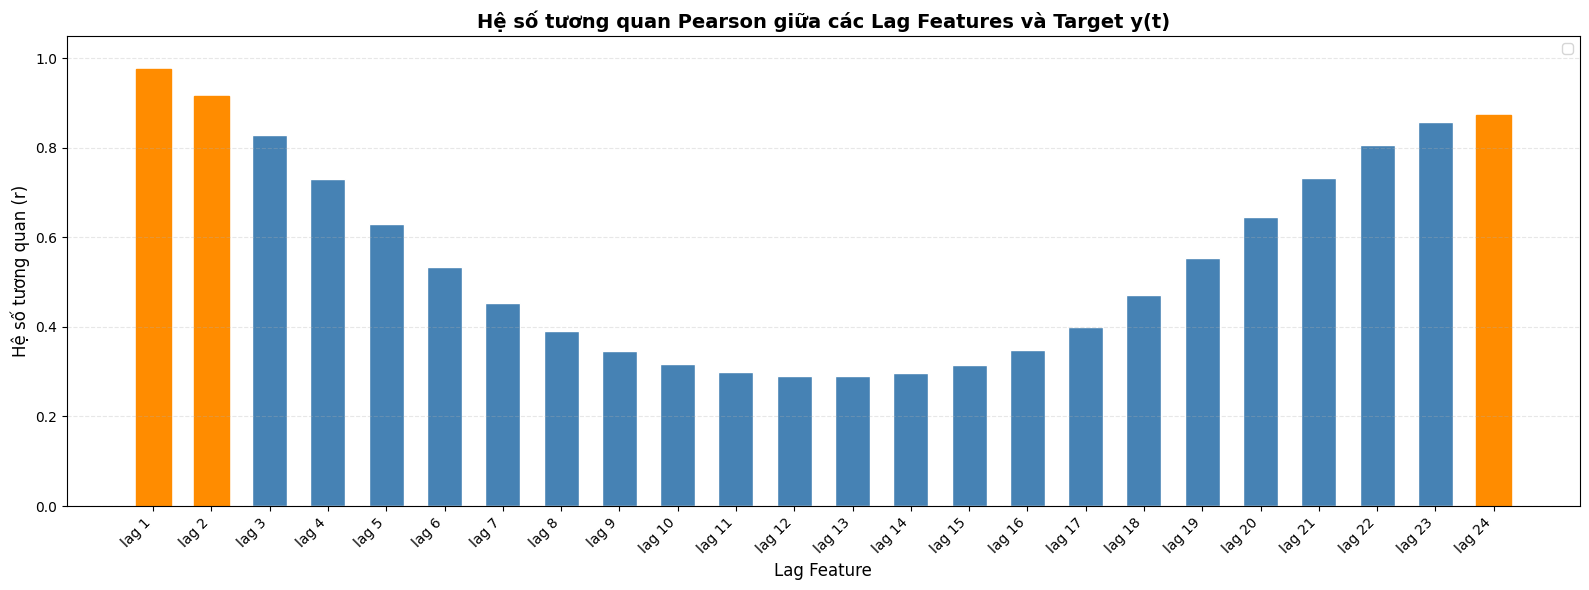

In [171]:
target_col = 'y' if 'y' in df_lag.columns else 'AEP_MW'
# Tìm tất cả các cột bắt đầu bằng 'lag' trong DataFrame
lag_col = [col for col in df_lag.columns if col.startswith('lag') and col != target_col]

correlative = df_lag[lag_col + [target_col]].corr()[target_col].drop(target_col)

fig, ax = plt.subplots(figsize=(16, 6))

bars = ax.bar(lag_col, correlative.values, color='steelblue', edgecolor='white', width=0.6)
# Tô màu cam nổi bật cho top 3 lag có tương quan cao nhất
top3_lags = correlative.nlargest(3).index
for i, bar in enumerate(bars):
    if lag_col[i] in top3_lags:
        bar.set_color('darkorange')

ax.set_title('Hệ số tương quan Pearson giữa các Lag Features và Target y(t)', fontsize=14, fontweight='bold')
ax.set_xlabel('Lag Feature', fontsize=12)
ax.set_ylabel('Hệ số tương quan (r)', fontsize=12)
ax.set_ylim(0, 1.05)  # Trục tung từ 0 đến 1.05 cho thoáng
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(loc='upper right')
# Xoay nhãn trục X cho dễ đọc
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Bước 3: Chia X-y

In [172]:
feature_col=[col for col in df_lag.columns if col not in ['y']]
X=df_lag[feature_col]

y=df_lag['y']#lấy riêng cột y
print(f"Kích thước ma trận đặc trưng X: {X.shape}")
print(f"Kích thước biến mục tiêu y: {y.shape}")
print("Thời gian bắt đầu:", X.index.min())
print("Thời gian kết thúc:", X.index.max())
X.head()


Kích thước ma trận đặc trưng X: (121245, 24)
Kích thước biến mục tiêu y: (121245,)
Thời gian bắt đầu: 2004-10-02 01:00:00
Thời gian kết thúc: 2018-08-03 00:00:00


,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 9,lag 10,...,lag 15,lag 16,lag 17,lag 18,lag 19,lag 20,lag 21,lag 22,lag 23,lag 24
Datetime,,,,,,,,,,,,,,,,,,,,,
2004-10-02 01:00:00,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,...,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
2004-10-02 02:00:00,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,...,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2004-10-02 03:00:00,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,...,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
2004-10-02 04:00:00,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,...,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
2004-10-02 05:00:00,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,...,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


* Sau khi chia X-y sẽ lưu vào DATA/processed/''

In [173]:
#lưu dữ liệu đã tách thành các file 
out_dir=os.path.join('..', 'DATA', 'processed')
x_path=os.path.join(out_dir, 'X_lag.csv')
X.to_csv(x_path)
print(f"Đá lưu ma trận đặc tưng X_lag tại: {x_path}")

y_path=os.path.join(out_dir, 'y.csv')
y.to_csv(y_path)
print(f"Đã lưu biến mục tiêu y tại: {y_path}")

Đá lưu ma trận đặc tưng X_lag tại: ..\DATA\processed\X_lag.csv
Đã lưu biến mục tiêu y tại: ..\DATA\processed\y.csv


* p = 24: sử dụng 24 giá trị tiêu thụ điện trước đó làm đặc trưng.

* X: gồm 24 cột lag_1 đến lag_24.

* y: là giá trị AEP_MW tại thời điểm hiện tại.

* 24 dòng đầu tiên bị loại vì không đủ lịch sử để tạo đủ 24 lag.

* Các timestamp trùng được gộp bằng trung bình; dữ liệu vẫn còn một số khoảng cách 2 giờ sau khi xử lý. Vì vậy, lag được hiểu là 24 quan sát 
trước đó, không đảm bảo luôn là đúng 24 giờ đồng hồ trước đó tại các đoạn có giờ khuyết. 

## Bước 4: Chia train/test theo thời gian
* Mục tiêu: Chia dữ liệu đầu vào X và biến mục tiêu y thành tập huấn luyện (Train) và tập kiểm tra (Test) theo đúng thứ tự thời gian.

* Notebook sử dụng kết quả từ Bước 2 và Bước 3:

  * X_lag_p24.csv: 24 đặc trưng trễ lag_1 đến lag_24.
  * y_AEP_MW.csv: giá trị mục tiêu AEP_MW.
  * Tỷ lệ chia: 80% Train – 20% Test.
  * Không xáo trộn dữ liệu (shuffle=False); 80% quan sát cũ hơn dùng để huấn luyện, 20% quan sát mới hơn ở cuối chuỗi dùng để kiểm tra.

In [174]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os 
import seaborn as sns
import json
from pathlib import Path# dùng để làm việc với đường dẫn

* Gọi lại x_lag và y để chia train/test

In [175]:
x_path = os.path.join('..', 'DATA', 'processed', 'X_lag.csv')
y_path = os.path.join('..', 'DATA', 'processed', 'y.csv')
# Sử dụng index_col=0 (lấy ngay cột đầu tiên làm index) kèm parse_dates=True
X = pd.read_csv(x_path, index_col=0, parse_dates=True)
y = pd.read_csv(y_path, index_col=0, parse_dates=True)
# Lấy cột giá trị y dạng Series
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]
print(f"Đã gọi lại file X_lag.csv: {X.shape}")
print(f"Đã gọi lại file y.csv    : {y.shape}")

Đã gọi lại file X_lag.csv: (121245, 24)
Đã gọi lại file y.csv    : (121245,)


* Check data trước khi chia

In [176]:
# Kiểm tra số lượng mẫu, thứ tự thời gian và sự tương ứng giữa X với y
print("X và y có cùng số mẫu:", len(X) == len(y))
print("X và y có cùng chỉ mục:", X.index.equals(y.index))
print("Index X tăng dần:", X.index.is_monotonic_increasing)
print("Timestamp trùng trong X:", X.index.has_duplicates)
print("Missing values trong X:", int(X.isna().sum().sum()))
print("Missing values trong y:", int(y.isna().sum()))

# Dừng chương trình nếu dữ liệu không đáp ứng điều kiện
assert len(X) == len(y), "X và y không có cùng số lượng mẫu!"
assert X.index.equals(y.index), "Chỉ mục thời gian của X và y không khớp!"
assert X.index.is_monotonic_increasing, "Dữ liệu chưa được sắp xếp tăng dần theo thời gian!"
assert not X.index.has_duplicates, "Chỉ mục thời gian đang có timestamp trùng!"
assert X.isna().sum().sum() == 0, "X còn giá trị thiếu!"
assert y.isna().sum() == 0, "y còn giá trị thiếu!"

print("Dữ liệu hợp lệ, sẵn sàng chia Train/Test.")

X và y có cùng số mẫu: True
X và y có cùng chỉ mục: True
Index X tăng dần: True
Timestamp trùng trong X: False
Missing values trong X: 0
Missing values trong y: 0
Dữ liệu hợp lệ, sẵn sàng chia Train/Test.


In [177]:
# Khai báo tỷ lệ dữ liệu dùng để huấn luyện
train_ratio = 0.80

# Xác định vị trí chia theo số lượng mẫu
split_idx = int(len(X) * train_ratio)

# Chia dữ liệu theo vị trí, giữ nguyên thứ tự thời gian
X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()
y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

print("Vị trí chia:", split_idx)
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test :", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test :", y_test.shape)

Vị trí chia: 96996
Kích thước X_train: (96996, 24)
Kích thước X_test : (24249, 24)
Kích thước y_train: (96996,)
Kích thước y_test : (24249,)


* Check kết quả sau khi chia

In [178]:
# Kiểm tra số lượng mẫu sau khi chia
total_samples = len(X_train) + len(X_test)

print(f"Tổng số mẫu ban đầu: {len(X)}")
print(f"Số mẫu Train: {len(X_train)} ({len(X_train) / len(X) * 100:.2f}%)")
print(f"Số mẫu Test : {len(X_test)} ({len(X_test) / len(X) * 100:.2f}%)")
print(f"Tổng Train + Test: {total_samples}")

print("\nKhoảng thời gian của từng tập:")
print("Train:", X_train.index.min(), "->", X_train.index.max())
print("Test :", X_test.index.min(), "->", X_test.index.max())

# Đảm bảo Train nằm trước Test và không có giao nhau về chỉ mục
assert len(X_train) > 0 and len(X_test) > 0, "Train hoặc Test đang rỗng!"
assert X_train.index.max() < X_test.index.min(), "Có nguy cơ trộn lẫn thứ tự thời gian!"
assert X_train.index.intersection(X_test.index).empty, "Train và Test bị trùng timestamp!"
assert X_train.index.equals(y_train.index), "Index X_train và y_train không khớp!"
assert X_test.index.equals(y_test.index), "Index X_test và y_test không khớp!"
assert total_samples == len(X), "Số mẫu sau chia không bằng dữ liệu ban đầu!"

print("\nKết luận: Chia Train/Test theo thời gian thành công.")

Tổng số mẫu ban đầu: 121245
Số mẫu Train: 96996 (80.00%)
Số mẫu Test : 24249 (20.00%)
Tổng Train + Test: 121245

Khoảng thời gian của từng tập:
Train: 2004-10-02 01:00:00 -> 2015-10-27 12:00:00
Test : 2015-10-27 13:00:00 -> 2018-08-03 00:00:00

Kết luận: Chia Train/Test theo thời gian thành công.


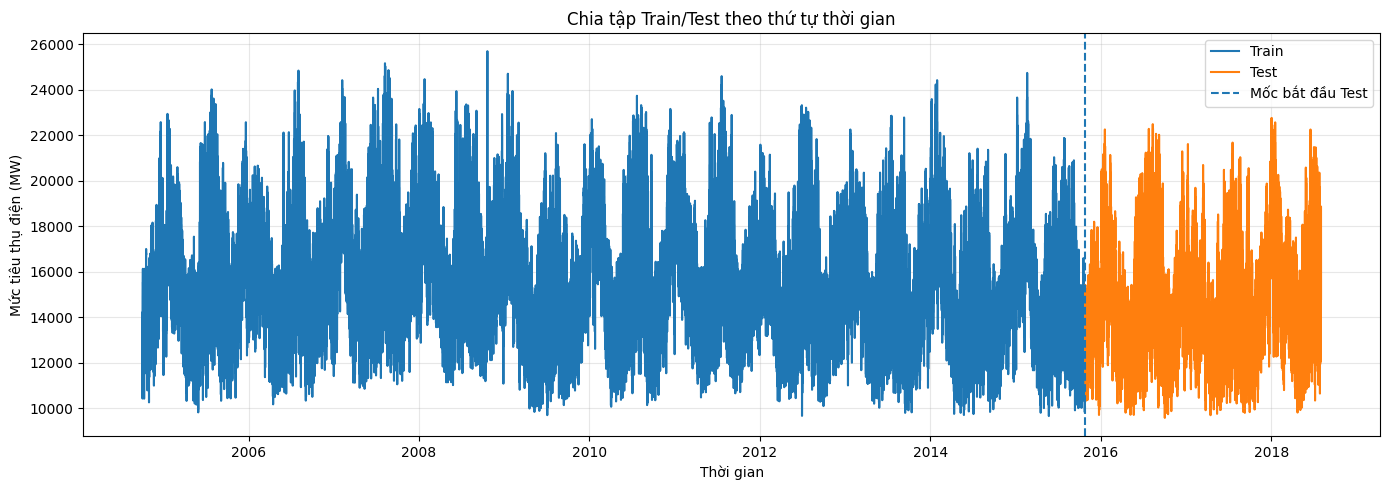

In [179]:
plt.figure(figsize=(14, 5))
plt.plot(y_train.index, y_train, label="Train")
plt.plot(y_test.index, y_test, label="Test")
plt.axvline(X_test.index[0], linestyle="--", label="Mốc bắt đầu Test")
plt.title("Chia tập Train/Test theo thứ tự thời gian")
plt.xlabel("Thời gian")
plt.ylabel("Mức tiêu thụ điện (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

* Lưu dữ liệu sau khi chia train/test dưới dạng file csv

In [180]:
# Tạo thư mục đầu ra; hỗ trợ chạy từ thư mục gốc repo hoặc notebooks/
if Path("DATA").exists():
    output_dir = Path("DATA/processed")
else:
    output_dir = Path("../DATA/processed")

output_dir.mkdir(parents=True, exist_ok=True)

# Lưu riêng từng tập để sử dụng ở Bước 5 – huấn luyện mô hình
X_train.to_csv(output_dir / "X_train.csv", index_label="Datetime")
X_test.to_csv(output_dir / "X_test.csv", index_label="Datetime")
y_train.to_frame(name="AEP_MW").to_csv(output_dir / "y_train.csv", index_label="Datetime")
y_test.to_frame(name="AEP_MW").to_csv(output_dir / "y_test.csv", index_label="Datetime")

print("Đã lưu các tệp tại:", output_dir.resolve())
for filename in ["X_train.csv", "X_test.csv", "y_train.csv", "y_test.csv"]:
    print("-", filename)

Đã lưu các tệp tại: C:\Programming_Language\time_series\xgboost-time-series-lab2\DATA\processed
- X_train.csv
- X_test.csv
- y_train.csv
- y_test.csv


In [181]:
# Điều chỉnh bố cục biểu đồ
plt.tight_layout()
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)
# Lưu biểu đồ với chất lượng cao
figure_path = figure_dir / "train_test_split.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
# Hiển thị biểu đồ
plt.show()
print("Đã lưu biểu đồ tại:", figure_path.resolve())

<Figure size 640x480 with 0 Axes>

Đã lưu biểu đồ tại: C:\Programming_Language\time_series\xgboost-time-series-lab2\reports\figures\train_test_split.png


## Bước 5: Huấn luyện mô hình XGboost
* Mục tiêu

  * Đọc dữ liệu Train đã chia ở Bước 4.

  * Khởi tạo XGBRegressor với bộ tham số ban đầu.

  * Huấn luyện mô hình trên (X_train, y_train).
  * Đo thời gian huấn luyện và theo dõi RMSE qua từng vòng boosting để quan sát quá trình hội tụ.

In [182]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
import os

* Load data đã lưu

In [183]:
candidate_dirs =[
    Path("DATA/processed"),
    Path("../DATA/processed"),
    Path("DATA/processed"),
    Path("../DATA/processed"),
]
data_dir = next((p for p in candidate_dirs if p.exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy DATA/processed. Hãy chạy Bước 4 và kiểm tra thư mục dữ liệu."
    )

x_train_path = data_dir / "X_train.csv"
y_train_path = data_dir / "y_train.csv"

for path in [x_train_path, y_train_path]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp: {path}")

print("Thư mục dữ liệu:", data_dir.resolve())

Thư mục dữ liệu: C:\Programming_Language\time_series\xgboost-time-series-lab2\DATA\processed


* Đọc dữ liệu train/test

In [184]:
X_train_df = pd.read_csv(x_train_path)
y_train_df = pd.read_csv(y_train_path)
# Kiểm tra dữ liệu X và y có cùng số dòng, cùng thứ tự thời gian
if len(X_train_df) != len(y_train_df):
    raise ValueError("X_train và y_train không có cùng số lượng mẫu.")
feature_cols = [col for col in X_train_df.columns if col.startswith("lag ")]
X_train = X_train_df[feature_cols]
# Lấy cột giá trị mục tiêu (nếu cột tên 'AEP_MW' hoặc 'y')
target_col = "AEP_MW" if "AEP_MW" in y_train_df.columns else y_train_df.columns[-1]
y_train = y_train_df[target_col]
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"Số đặc trưng: {len(feature_cols)}")

display(X_train.head())
display(y_train.head())

X_train: (96996, 24)
y_train: (96996,)
Số đặc trưng: 24


,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 9,lag 10,...,lag 15,lag 16,lag 17,lag 18,lag 19,lag 20,lag 21,lag 22,lag 23,lag 24
0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,...,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
1,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,...,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,...,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
3,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,...,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
4,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,...,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


0    12260.0
1    11672.0
2    11352.0
3    11177.0
4    11142.0
Name: AEP_MW, dtype: float64

In [185]:
# Sửa thành đường dẫn liền có dấu gạch chéo /
X_test_df = pd.read_csv('../DATA/processed/X_test.csv')
y_test_df = pd.read_csv('../DATA/processed/y_test.csv')

# Lấy 24 cột đặc trưng lag tương ứng và cột mục tiêu
X_test = X_test_df[feature_cols]
y_test = y_test_df[target_col]

print(f"X_test kích thước : {X_test.shape}")
print(f"y_test kích thước : {y_test.shape}")

X_test kích thước : (24249, 24)
y_test kích thước : (24249,)


## Khởi tạo mô hình XGBoost

Bộ tham số ban đầu được chọn để làm baseline, chưa phải tham số tối ưu:

| Tham số | Giá trị | Ý nghĩa |
| :--- | :---: | :--- |
| `n_estimators` | 300 | Số cây boosting tối đa |
| `learning_rate` | 0.05 | Mức đóng góp của mỗi cây |
| `max_depth` | 6 | Độ sâu tối đa của cây |
| `subsample` | 0.8 | Tỷ lệ mẫu dùng để xây mỗi cây |
| `colsample_bytree` | 0.8 | Tỷ lệ đặc trưng dùng cho mỗi cây |
| `objective` | `reg:squarederror` | Hàm mục tiêu hồi quy |
| `eval_metric` | `rmse` | Theo dõi sai số căn RMSE |
| `random_state` | 42 | Cố định seed để tăng khả năng tái lập |
| `n_jobs` | -1 | Sử dụng các lõi CPU khả dụng |

`n_estimators` là số vòng boosting. Ở mỗi vòng, XGBoost bổ sung cây mới để cải thiện dự báo.

In [186]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
)

In [187]:
start_time = time.perf_counter()
model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train)],
    verbose=False,
)

training_seconds = time.perf_counter() - start_time

print(f"Thời gian huấn luyện: {training_seconds:.2f} giây")
print(f"Số cây đã huấn luyện: {model.n_estimators}")

Thời gian huấn luyện: 7.65 giây
Số cây đã huấn luyện: 300


RMSE Train ban đầu (round 1): 2464.6715
RMSE Train cuối cùng (round 300): 185.9946


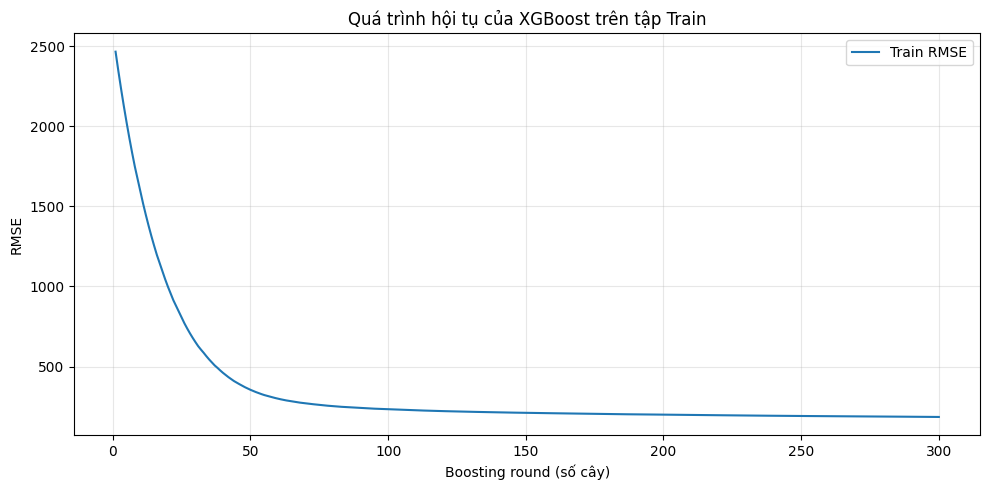

In [188]:
# Lấy RMSE của tập Train ở mỗi boosting round
evals_result = model.evals_result()
train_rmse = evals_result["validation_0"]["rmse"]

print(f"RMSE Train ban đầu (round 1): {train_rmse[0]:.4f}")
print(f"RMSE Train cuối cùng (round {len(train_rmse)}): {train_rmse[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_rmse) + 1), train_rmse, label="Train RMSE")
plt.xlabel("Boosting round (số cây)")
plt.ylabel("RMSE")
plt.title("Quá trình hội tụ của XGBoost trên tập Train")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

## Nhận xét quá trình huấn luyện
* Sau khi chạy notebook, ghi nhận:

  * Thời gian huấn luyện: giá trị được in ở Bước 4 (phụ thuộc cấu hình máy).
  * RMSE ở vòng đầu và vòng cuối: giá trị được in ra thành biểu đồ.
  * Quan sát đồ thị: RMSE giảm nhanh ở giai đoạn đầu rồi giảm chậm/dần ổn định hay còn dao động.
* Cách diễn giải: RMSE Train giảm cho thấy mô hình đang học các mẫu trong tập Train. Nếu RMSE tiếp tục giảm nhưng lỗi trên tập Validation/Test tăng, có thể xảy ra overfitting; cần đánh giá lại. Không kết luận mô hình tổng quát 

In [190]:
os.makedirs('../models', exist_ok=True)
# Đường dẫn file mô hình JSON
JSON_MODEL_PATH = '../models/xgboost_model.json'
# Dùng hàm save_model chuẩn của XGBoost để xuất ra JSON
model.save_model(JSON_MODEL_PATH)
print(f"Đã lưu mô hình XGBoost thành công vào file JSON tại: {JSON_MODEL_PATH}")

Đã lưu mô hình XGBoost thành công vào file JSON tại: ../models/xgboost_model.json


## Bước 6: Dự đoán và đánh giá
* Notebook này thực hiện:

  * Nạp tập dữ liệu kiểm thử (Test Set: 24,249 dòng, 24 đặc trưng) và model XGBoost đã huấn luyện.
  * Dự báo trên tập Train và tập Test.  
  * Đo lường các chỉ số MAE, RMSE, MAPE, R2-score.
  * Trực quan hóa kết quả dự báo (Actual vs Predicted) và phân tích phần dư (Residuals).

In [191]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [192]:
from xgboost import XGBRegressor
# Đường dẫn thư mục
PROCESSED_DATA_PATH = "../DATA/processed"
MODEL_PATH = "../models"

# 1. Đọc dữ liệu từ thư mục DATA/processed (file CSV)
X_train = pd.read_csv(f"{PROCESSED_DATA_PATH}/X_train.csv", index_col=0)
X_test = pd.read_csv(f"{PROCESSED_DATA_PATH}/X_test.csv", index_col=0)
y_train = pd.read_csv(f"{PROCESSED_DATA_PATH}/y_train.csv", index_col=0).squeeze()
y_test = pd.read_csv(f"{PROCESSED_DATA_PATH}/y_test.csv", index_col=0).squeeze()

# 2. Tải mô hình đã lưu từ file JSON
model = XGBRegressor()
model.load_model(f"{MODEL_PATH}/xgboost_model.json")

print("Dữ liệu và mô hình đã được tải thành công!")
print(f"Kích thước X_test: {X_test.shape}")
print(f"Kích thước y_test: {y_test.shape}")

Dữ liệu và mô hình đã được tải thành công!
Kích thước X_test: (24249, 24)
Kích thước y_test: (24249,)


In [193]:
# Dự báo trên cả 2 tập để đối chiếu Overfitting
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Chuyển đổi về Series giữ nguyên index thời gian để tiện vẽ biểu đồ
y_test_pred_series = pd.Series(y_test_pred, index=y_test.index, name="Predicted")

In [194]:
def calculate_metrics(y_true, y_pred, set_name="Test Set"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    # Tránh chia cho 0 khi tính MAPE
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-6, y_true))) * 100
    r2 = r2_score(y_true, y_pred)
    
    return {
        "Dataset": set_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "MAPE (%)": round(mape, 2),
        "R2 Score": round(r2, 4)
    }

# Tính toán chỉ số cho cả hai tập
metrics_train = calculate_metrics(y_train, y_train_pred, "Train Set")
metrics_test = calculate_metrics(y_test, y_test_pred, "Test Set")

# Tổng hợp bảng so sánh để điền vào 05_evaluation.md
df_metrics = pd.DataFrame([metrics_train, metrics_test])
display(df_metrics)

,Dataset,MAE,RMSE,MAPE (%),R2 Score
0,Train Set,138.4876,185.9946,0.89,0.9948
1,Test Set,147.7998,200.1714,1.02,0.9933


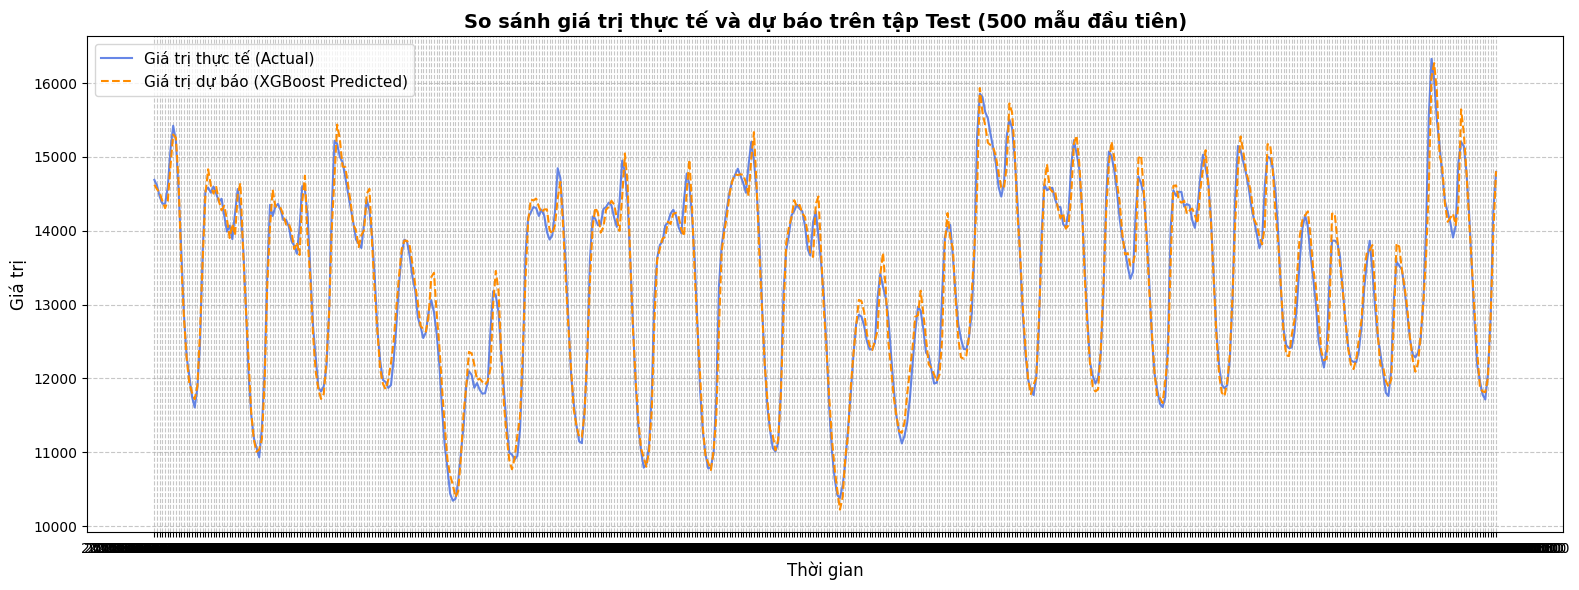

In [196]:
plt.figure(figsize=(16, 6))

# Lấy một khoảng thời gian cụ thể (ví dụ 500 mẫu đầu của Test Set để nhìn rõ đường nét)
SAMPLE_RANGE = 500  

plt.plot(y_test.index[:SAMPLE_RANGE], y_test.iloc[:SAMPLE_RANGE], label="Giá trị thực tế (Actual)", color="royalblue", alpha=0.8, linewidth=1.5)
plt.plot(y_test.index[:SAMPLE_RANGE], y_test_pred_series.iloc[:SAMPLE_RANGE], label="Giá trị dự báo (XGBoost Predicted)", color="darkorange", linestyle="--", linewidth=1.5)

plt.title(f"So sánh giá trị thực tế và dự báo trên tập Test ({SAMPLE_RANGE} mẫu đầu tiên)", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian", fontsize=12)
plt.ylabel("Giá trị", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()

# Lưu biểu đồ để chèn vào docs/reports
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/actual_vs_predicted.png", dpi=300)
plt.show()


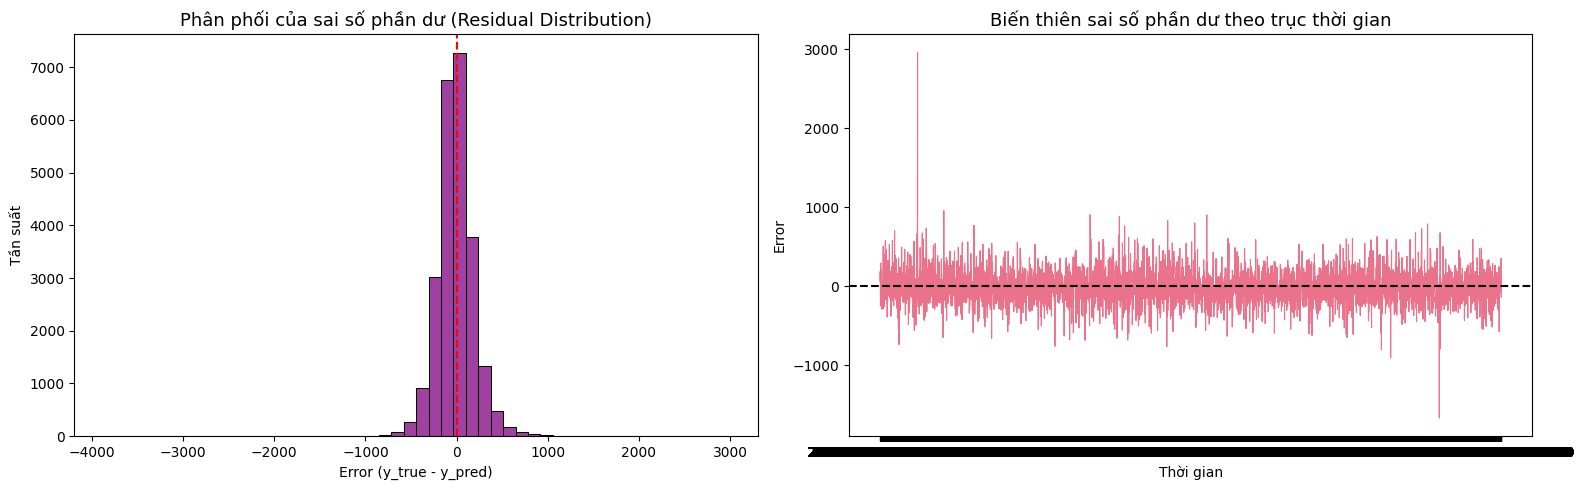

In [197]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Tắt kde=True hoặc chỉ lấy mẫu để vẽ KDE siêu tốc
sns.histplot(residuals, kde=False, ax=axes[0], color="purple", bins=50)
axes[0].set_title("Phân phối của sai số phần dư (Residual Distribution)", fontsize=13)
axes[0].set_xlabel("Error (y_true - y_pred)")
axes[0].set_ylabel("Tần suất")
axes[0].axvline(x=0, color="red", linestyle="--")

# 2. Giảm bớt số điểm vẽ biểu đồ thời gian (downsample hoặc lấy 1000-2000 điểm tiêu biểu)
# Hoặc vẽ nhanh bằng plot thông thường
axes[1].plot(y_test.index[::5], residuals[::5], color="crimson", alpha=0.6, linewidth=0.8)
axes[1].axhline(y=0, color="black", linestyle="--")
axes[1].set_title("Biến thiên sai số phần dư theo trục thời gian", fontsize=13)
axes[1].set_xlabel("Thời gian")
axes[1].set_ylabel("Error")

plt.tight_layout()

# Giảm dpi xuống 120-150 (đủ nét cho báo cáo/markdown và lưu rất nhanh)
plt.savefig("../reports/figures/residual_analysis.png", dpi=150)
plt.show()

C:\Users\Windows\AppData\Local\Temp\ipykernel_22552\2673361658.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance.head(15), y=feature_importance.head(15).index, palette="viridis")


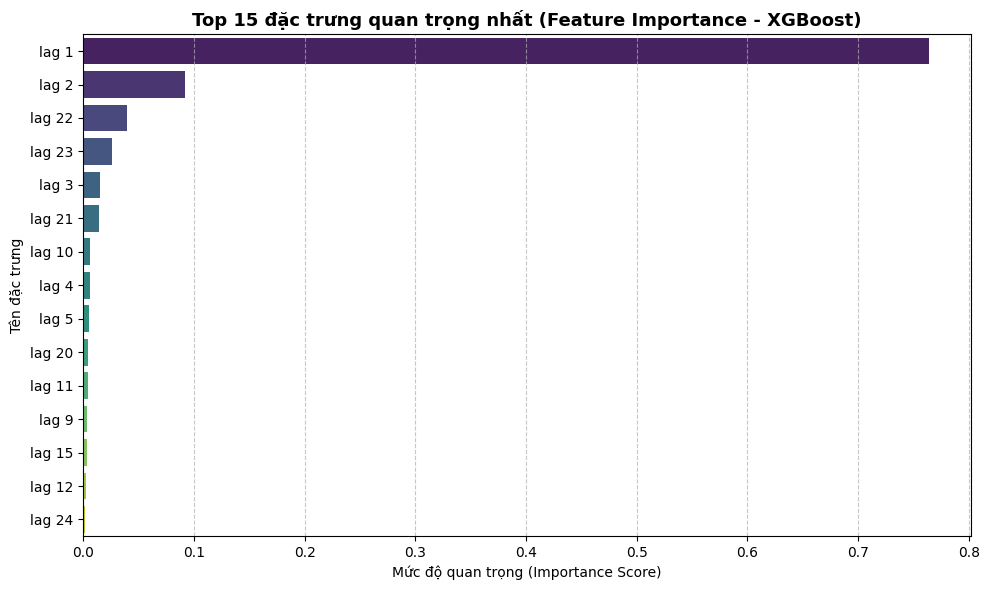

In [198]:
# Lấy top 15 đặc trưng ảnh hưởng nhiều nhất đến quyết định của cây XGBoost
feature_importance = pd.Series(model.feature_importances_, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.head(15), y=feature_importance.head(15).index, palette="viridis")
plt.title("Top 15 đặc trưng quan trọng nhất (Feature Importance - XGBoost)", fontsize=13, fontweight="bold")
plt.xlabel("Mức độ quan trọng (Importance Score)")
plt.ylabel("Tên đặc trưng")
plt.grid(axis='x', linestyle="--", alpha=0.7)
plt.tight_layout()

plt.savefig("../reports/figures/feature_importance.png", dpi=300)
plt.show()